# CS 430 Assignment 3: SLCM Rent Arrears Classification

Goal Predict whether a household has $3,000 or more in past due rent using five classification models.

Now the question is: Can household and housing
information help identify households with $3,000 or more in past due rent?

Part 1 – Understand the Classification Problem (15 points)
1. Explore the dataset (7 points)

• Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.

• Identify one numerical and one categorical feature.

• Answer: Why must past_due_rent be excluded from the input features?

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Load the SLCM dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Ass3/SLCM_rent_arrears_student_clean(2).csv")
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Display the data
print("Data shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isna().sum())
print("\nNumerical feature: monthly_rent")
print("Categorical feature: employment_status")

Data shape: (1754, 14)

Column names: ['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']

Missing values per column:
record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64

Numerical feature: monthly_rent
Categorical feature: employment_status


**Why must past_due_rent be excluded?**

One numerical feature is monthly_rent and one categorical feature is employment_status. We need to exclude past_due_rent from our input features because its what we are using to create our target variable high_arrears. Including it would give the model information it wouldnt normally have when making a prediction and lead to data leakage.




### 2. Create the target (8 points)

Part 2 – Prepare the Data (25 points)

3. Select features and split (10 points)

• Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.

• Split the data once into training and testing sets.

• Answer: Why do we keep a separate test set?

high_arrears
0    1210
1     544
Name: count, dtype: int64


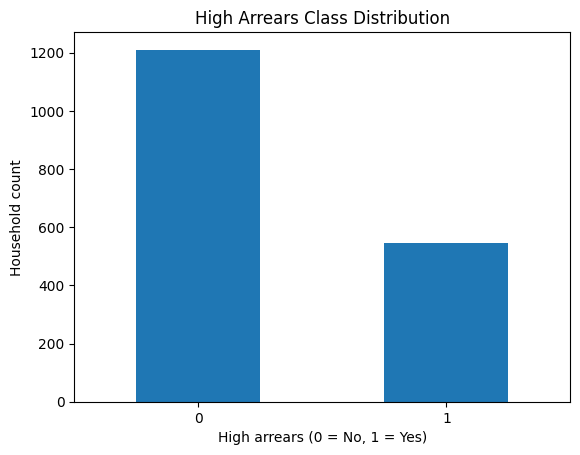

In [ ]:
# Create the classification target and split high arrers and pastdue rent
df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)
print(df["high_arrears"].value_counts())

df["high_arrears"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("High arrears (0 = No, 1 = Yes)")
plt.ylabel("Household count")
plt.title("High Arrears Class Distribution")
plt.xticks(rotation=0)
plt.show()

Interpretation Which class is larger? Why might accuracy alone be misleading

Class 0 is the larger class with around 1,200 households compared to around 550 in class 1. Accuracy alone can be misleading because the model could predict most households as class 0 and still have a high accuracy. This would cause the model to miss households with high arrears which is the group we are trying to find.

## Part 2 – Prepare the Data (25 points)

3. Select features and split (10 points)

• Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.

• Split the data once into training and testing sets.

• Answer: Why do we keep a separate test set?

In [ ]:
# Separate input features and the target
X = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]

# Use the same split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training target counts:")
print(y_train.value_counts())
print("Testing target counts:")
print(y_test.value_counts())

Training set: (1403, 12)
Testing set: (351, 12)
Training target counts:
high_arrears
0    968
1    435
Name: count, dtype: int64
Testing target counts:
high_arrears
0    242
1    109
Name: count, dtype: int64


Why do we keep a separate test set?
We keep a separate test set to evaluate how well our model performs on data it hasnt already seen. By using 1,403 households for training and 351 for testing we can see how well the model generalizes to new data. This also helps us identify if the model is overfitting rather than actually learning patterns from the data.





4. Build one reusable preprocessor (15 points)

• Identify numerical and categorical columns with select_dtypes.

• Numerical: fill missing values using median and apply StandardScaler.

• Categorical: fill missing values using most_frequent and apply OneHotEncoder
(handle_unknown="ignore").

• Combine with ColumnTransformer. You may reuse the class example.

• Answer: Why is scaling helpful for KNN and SVC?

In [ ]:
# Identify feature types
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

# Same preprocessing for all five models
num = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)
# use a simple imputer and a one hot encoder for the piple line
cat = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)

prep = ColumnTransformer([
    ("num", num, num_cols),
    ("cat", cat, cat_cols)
])

Numerical columns: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical columns: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


Why is scaling helpful for KNN and SVC?

Scaling is important for KNN and SVC because both models use distances between data points to make predictions. Without scaling larger values like monthly_rent and monthly_household_income could have a greater impact than smaller values like adults_in_household.

Part 3 – Train and Compare Five Models (45 points)
5. Train the five classifiers (20 points)

• Build five pipelines with the same preprocessor, the same training set, and these models:

• Logistic Regression: LogisticRegression(max_iter=1000)

• KNN: KNeighborsClassifier(n_neighbors=5)

• Decision Tree: DecisionTreeClassifier(max_depth=5, random_state=42)

• Random Forest: RandomForestClassifier(n_estimators=100, random_state=42)

• Support Vector Classifier: SVC()

• Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not
need a loop or custom functions.

#### Logistic Regression

In [ ]:
# write the logistic regression and fit with the piple line
logistic = make_pipeline(prep, LogisticRegression(max_iter=1000))
logistic.fit(X_train, y_train)
logistic_pred = logistic.predict(X_test)

logistic_accuracy = accuracy_score(y_test, logistic_pred)
logistic_recall = recall_score(y_test, logistic_pred, pos_label=1, zero_division=0)
logistic_f1 = f1_score(y_test, logistic_pred, pos_label=1, zero_division=0)

print("Accuracy:", round(logistic_accuracy, 3))
print("Recall (class 1):", round(logistic_recall, 3))
print("F1 (class 1):", round(logistic_f1, 3))

Accuracy: 0.695
Recall (class 1): 0.303
F1 (class 1): 0.382


#### KNN

In [ ]:
# write the knn and fit with the piple line
knn = make_pipeline(prep, KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_recall = recall_score(y_test, knn_pred, pos_label=1, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, pos_label=1, zero_division=0)

print("Accuracy:", round(knn_accuracy, 3))
print("Recall (class 1):", round(knn_recall, 3))
print("F1 (class 1):", round(knn_f1, 3))

Accuracy: 0.681
Recall (class 1): 0.376
F1 (class 1): 0.423


#### Decision Tree

In [ ]:
# # write the Decision tree and fit with the piple line
tree = make_pipeline(prep, DecisionTreeClassifier(max_depth=5, random_state=42))
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

tree_accuracy = accuracy_score(y_test, tree_pred)
tree_recall = recall_score(y_test, tree_pred, pos_label=1, zero_division=0)
tree_f1 = f1_score(y_test, tree_pred, pos_label=1, zero_division=0)

print("Accuracy:", round(tree_accuracy, 3))
print("Recall (class 1):", round(tree_recall, 3))
print("F1 (class 1):", round(tree_f1, 3))

Accuracy: 0.695
Recall (class 1): 0.33
F1 (class 1): 0.402


#### Random Forest

In [ ]:
# # write the random forest and fit with the piple line
forest = make_pipeline(prep, RandomForestClassifier(n_estimators=100, random_state=42))
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

forest_accuracy = accuracy_score(y_test, forest_pred)
forest_recall = recall_score(y_test, forest_pred, pos_label=1, zero_division=0)
forest_f1 = f1_score(y_test, forest_pred, pos_label=1, zero_division=0)

print("Accuracy:", round(forest_accuracy, 3))
print("Recall (class 1):", round(forest_recall, 3))
print("F1 (class 1):", round(forest_f1, 3))

Accuracy: 0.704
Recall (class 1): 0.321
F1 (class 1): 0.402


#### SVC

In [ ]:
# SVC
svc = make_pipeline(prep, SVC())
svc.fit(X_train, y_train)
svc_pred = svc.predict(X_test)

svc_accuracy = accuracy_score(y_test, svc_pred)
svc_recall = recall_score(y_test, svc_pred, pos_label=1, zero_division=0)
svc_f1 = f1_score(y_test, svc_pred, pos_label=1, zero_division=0)

print("Accuracy:", round(svc_accuracy, 3))
print("Recall (class 1):", round(svc_recall, 3))
print("F1 (class 1):", round(svc_f1, 3))

Accuracy: 0.707
Recall (class 1): 0.229
F1 (class 1): 0.327


### 6. Compare the models (10 points)

- Put the test results in a table with columns: Model, Accuracy, Recall, F1.
- Create one confusion matrix for the model with the highest test F1.
- **Answer:** Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

In [ ]:
# Compare the test-set scores
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree", "Random Forest", "SVC"],
    "Accuracy": [logistic_accuracy, knn_accuracy, tree_accuracy, forest_accuracy, svc_accuracy],
    "Recall": [logistic_recall, knn_recall, tree_recall, forest_recall, svc_recall],
    "F1": [logistic_f1, knn_f1, tree_f1, forest_f1, svc_f1]
})

print(results.round(3).to_string(index=False))

              Model  Accuracy  Recall    F1
Logistic Regression     0.695   0.303 0.382
                KNN     0.681   0.376 0.423
      Decision Tree     0.695   0.330 0.402
      Random Forest     0.704   0.321 0.402
                SVC     0.707   0.229 0.327


Best test F1 model: KNN


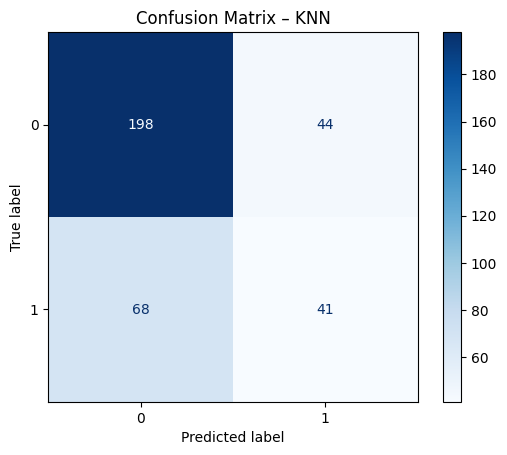

In [ ]:
# Confusion matrix for the model with the highest test F1
best_name = results.loc[results["F1"].idxmax(), "Model"]
model_predictions = {
    "Logistic Regression": logistic_pred,
    "KNN": knn_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred,
    "SVC": svc_pred
}

print("Best test F1 model:", best_name)
cm = confusion_matrix(y_test, model_predictions[best_name], labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1]).plot(cmap="Blues")
plt.title("Confusion Matrix – " + best_name)
plt.show()

Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

KNN was able to identify the highest proportion of high arrears households with a recall of 37.6%. Looking at the confusion matrix we can see that it correctly identified 41 households but failed to identify 68 that actually had high arrears. For SLCM this means that households who may be in serious need of assistance could be overlooked by the model.



7. Try a small GridSearchCV (15 points)

• Tune only two models on the training set with cv=3 and scoring="f1".

• For KNN, try n_neighbors = [3, 5, 7].

• For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100).

• Print best_params_ and best_score_ for each search. No extra charts or second
search are needed.

• Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

In [ ]:
# Grid search for KNN
knn_grid = {"kneighborsclassifier__n_neighbors": [3, 5, 7]}
knn_search = GridSearchCV(knn, knn_grid, cv=3, scoring="f1")
knn_search.fit(X_train, y_train)

print("Best KNN parameters:", knn_search.best_params_)
print("Best KNN CV F1:", round(knn_search.best_score_, 3))

Best KNN parameters: {'kneighborsclassifier__n_neighbors': 7}
Best KNN CV F1: 0.485


In [ ]:
# Grid search for Random Forest
forest_grid = {"randomforestclassifier__max_depth": [3, 5, None]}
forest_search = GridSearchCV(forest, forest_grid, cv=3, scoring="f1")
forest_search.fit(X_train, y_train)

print("Best Random Forest parameters:", forest_search.best_params_)
print("Best Random Forest CV F1:", round(forest_search.best_score_, 3))

Best Random Forest parameters: {'randomforestclassifier__max_depth': None}
Best Random Forest CV F1: 0.457


Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

KNN had the higher cross validation F1 score of 0.485 compared to Random Forest which had 0.457. This shows that KNN performed better when using 7 neighbors compared to the Random Forest model. We only use the training data for GridSearchCV because we want to keep the testing data seperate from the training process. Using the testing data could cause the model to overfit and give us a false understanding of how well it actually performs on new data it hasnt seen before.

## Part 4 – Explain the Results (15 points)

### 8. Interpret your comparison (8 points)

In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not accuracy alone. Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

I think KNN was the most promising model because it had the highest F1 score of 0.423 and recall of 0.376 showing it was better at identifying households with high arrears compared to the other models. Even though other models had higher accuracy KNN was able to identify more households that actually needed assistance. A more complex model didnt necessarily perform better as Random Forest and SVC both struggled more with identifying high arrears households. For SLCM the biggest concern would be false negatives where households who actually have high arrears are incorrectly identified as not having them. These errors could lead to families being overlooked and not receiving the proper assistance they may need.





### 9. Recommendation to SLCM (7 points)

Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model performed, one practical insight, and one limitation. State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

For SLCM we tried to predict which households had $3,000 or more in past due rent using information about their household and housing situation. KNN was our best performing model with an F1 score of 0.423 and was able to correctly identify 37.6% of households with high arrears. This shows that the model could potentially help SLCM identify households who may need additional assistance but still misses a large portion of those who need help. One major limitation is that the model isnt accurate enough at identifying these households and could lead to families being overlooked.


